In [1083]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import datetime as dt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score

In [1084]:
df = pd.read_csv('data/RRCA_baseflow.csv')

### Reformatting the dates from days since 01/01/0000 to M-D-Y
--------------------------------------------------------------

In [1085]:
baseflow_df = df.copy()
# offset is the number of days between 01/01/0000 and 01/01/1900 (693963)
offset = 693963
baseflow_df['days_since_1900'] = baseflow_df.Date - offset
baseflow_df['offset_date'] = pd.to_datetime(baseflow_df.days_since_1900.astype('int'), unit='D', origin=pd.Timestamp('1900-01-01'))
print(baseflow_df['offset_date'])

0       1945-11-30
1       1945-12-31
2       1946-01-28
3       1946-02-28
4       1946-03-30
           ...    
15586   1976-03-30
15587   1976-04-30
15588   1976-05-30
15589   1976-06-30
15590   1976-07-31
Name: offset_date, Length: 15591, dtype: datetime64[s]


### Preliminary Column Analysis (so we know what we're working with)
--------------------------------------------------------------------

**Where is our data from?**

Notes:
- The dataset is labeled *RRCA_baseflow.csv*
    - In the context of bodies of water, *RRCA* might refer to *Republican River Compact Administration*.
        - The *Republican River* is a river that runs east from Colorado through Nebraska and Kansas.
- It looks like the RRCA made a groundwater flow model to represent characteristics of the Republican River Basin.

Website: (https://www.republicanrivercompact.org/)

In [1086]:
print(f"Minimum x coordinate(...?): {min(baseflow_df['x'])}")
print(f"Maximum x coordinate: {max(baseflow_df['x'])}")
print(f"Minimum y coordinate: {min(baseflow_df['y'])}")
print(f"Maximum y coordinate: {max(baseflow_df['y'])}")

Minimum x coordinate(...?): 721870
Maximum x coordinate: 1941550
Minimum y coordinate: 14387040
Maximum y coordinate: 14767200


I'm not sure what to make off these positions/coordinates. They don't seem to be WGS84 coordinates.

In [1087]:
print(min(baseflow_df['offset_date']))
print(max(baseflow_df['offset_date']))

1939-09-30 00:00:00
2000-08-30 00:00:00


The dataset spans 1939-2000. This doesn't line up with the initial scope of the model (1918-2000).

Here's the documentation on the model: (https://www.republicanrivercompact.org/v12p/RRCAModelDocumentation.pdf)
After digging in the documentation, I found that the model works on the premise that there was no recharge from ground water irrigation prior to 1940 (pg. 14). (I'm sorry if that understanding misrepresents the paper)

In [1088]:
pre40s = baseflow_df[baseflow_df.offset_date< '1940-01-01']
print(pre40s[pre40s.Irrigation_pumping != 0])

Empty DataFrame
Columns: [Date, Segment_id, x, y, Evapotranspiration, Precipitation, Irrigation_pumping, Observed, days_since_1900, offset_date]
Index: []


So, the dataset is from the inaugural/2003 use of the model (also referred to as Version 12p). We can use this to explain the dataset and interpret certain variables (notably what the coordinates mean).

In [1089]:
display(baseflow_df)

,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,days_since_1900,offset_date
0,710732,144,1086190,14476800,0.59,18.99,0.0,0.145161,16769,1945-11-30
1,710763,144,1086190,14476800,0.97,29.63,0.0,0.445161,16800,1945-12-31
2,710791,144,1086190,14476800,1.34,29.63,0.0,1.332203,16828,1946-01-28
3,710822,144,1086190,14476800,1.79,29.63,0.0,2.932203,16859,1946-02-28
4,710852,144,1086190,14476800,8.23,29.63,0.0,3.728689,16889,1946-03-30
...,...,...,...,...,...,...,...,...,...,...
15586,721810,98,721870,14387040,0.00,0.00,0.0,0.298500,27847,1976-03-30
15587,721841,98,721870,14387040,0.00,0.00,0.0,0.211475,27878,1976-04-30
15588,721871,98,721870,14387040,0.00,0.00,0.0,0.122951,27908,1976-05-30
15589,721902,98,721870,14387040,0.00,0.00,0.0,0.120000,27939,1976-06-30


### WHAT HAPPEND in 1951?

--- Correlation Matrix ---
                    Evapotranspiration  Precipitation  Irrigation_pumping  \
Evapotranspiration            1.000000       0.428491           -0.495154   
Precipitation                 0.428491       1.000000           -0.154587   
Irrigation_pumping           -0.495154      -0.154587            1.000000   
Observed                      0.062248       0.270033            0.054757   

                    Observed  
Evapotranspiration  0.062248  
Precipitation       0.270033  
Irrigation_pumping  0.054757  
Observed            1.000000  

--- Yearly Summary (Head) ---
   Year  Evapotranspiration  Precipitation  Irrigation_pumping   Observed
0  1940            1.115714      12.902143            0.000000  34.152220
1  1941            3.054798      13.135954           -0.018842  63.461244
2  1942            3.001019      23.492778           -0.012034  90.321743
3  1943            3.123333      23.125000           -0.013724  93.813370
4  1944            3.829623    

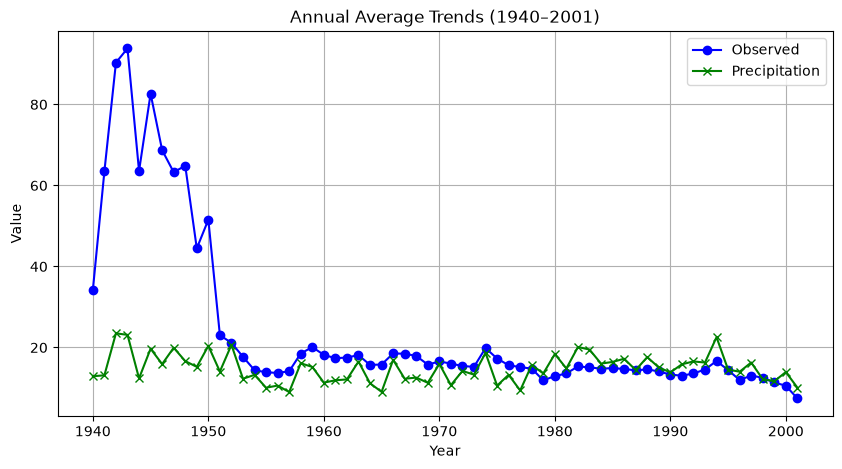

In [1090]:
df['datetime'] = pd.to_datetime(df['Date'].apply(dt.date.fromordinal))
df['Year'] = df['datetime'].dt.year
# 3. Correlation Analysis
corr_cols = ['Evapotranspiration', 'Precipitation', 'Irrigation_pumping', 'Observed']
corr_matrix = df[corr_cols].corr()
print('--- Correlation Matrix ---')
print(corr_matrix)

# 4. Temporal Aggregation (Yearly Mean)
yearly_df = df.groupby('Year')[corr_cols].mean().reset_index()
print('\n--- Yearly Summary (Head) ---')
print(yearly_df.head())

# 5. Spatial Aggregation (Segment-Specific Summary)
segment_summary = (
    df.groupby('Segment_id')[corr_cols]
    .agg(['mean', 'std', 'count'])
    .reset_index()
)
print('\n--- Segment Summary (Head) ---')
print(segment_summary.head())

# 6. Optional: Quick Plotting
plt.figure(figsize=(10, 5))
plt.plot(
    yearly_df['Year'], yearly_df['Observed'], marker='o', color='b', label='Observed'
)
plt.plot(
    yearly_df['Year'],
    yearly_df['Precipitation'],
    marker='x',
    color='g',
    label='Precipitation',
)
plt.title('Annual Average Trends (1940–2001)')
plt.xlabel('Year')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()

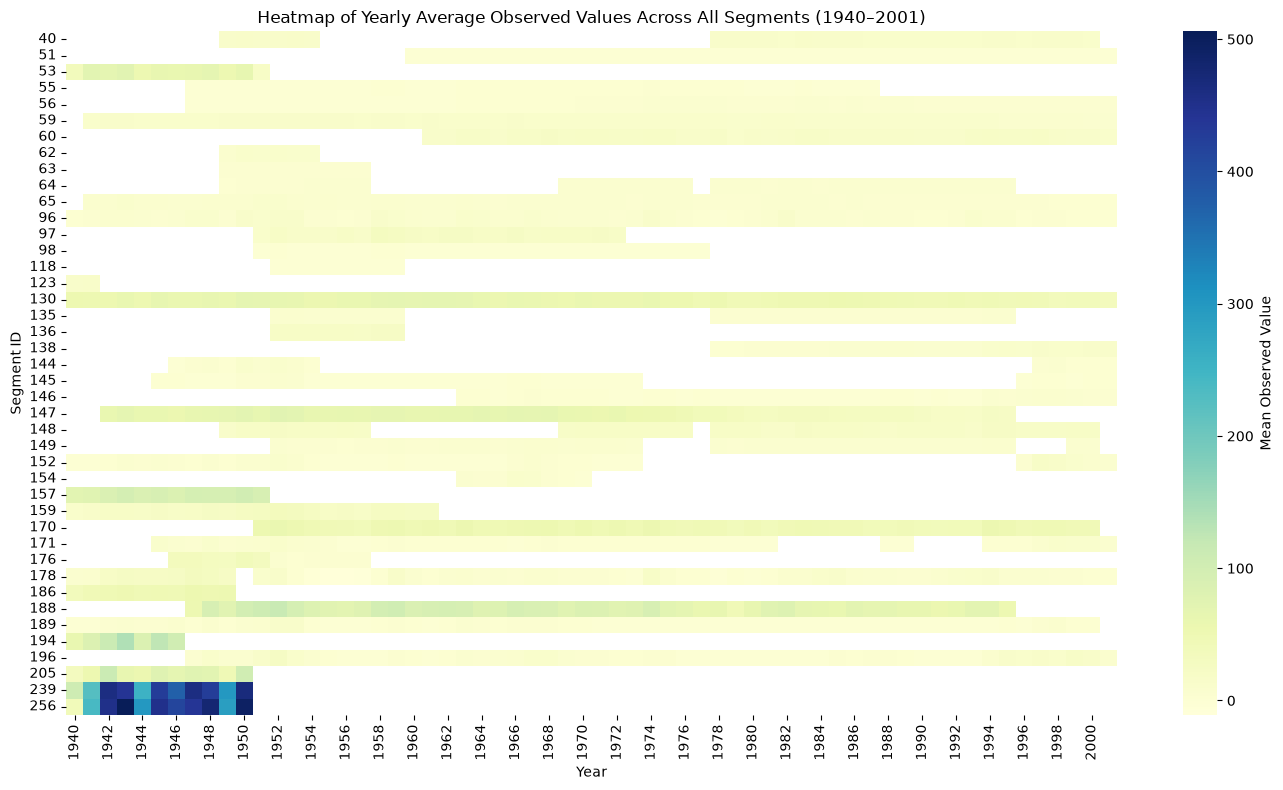

In [1091]:
# 2. Create a pivot table: Rows = Segment_id, Columns = Year, Values = Mean Observed
pivot_obs = df.pivot_table(
    index='Segment_id', columns='Year', values='Observed', aggfunc='mean'
)

# 3. Plot a Heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(pivot_obs, cmap='YlGnBu', cbar_kws={'label': 'Mean Observed Value'})
plt.title(
    'Heatmap of Yearly Average Observed Values Across All Segments (1940–2001)'
)
plt.xlabel('Year')
plt.ylabel('Segment ID')
plt.tight_layout()
plt.show()

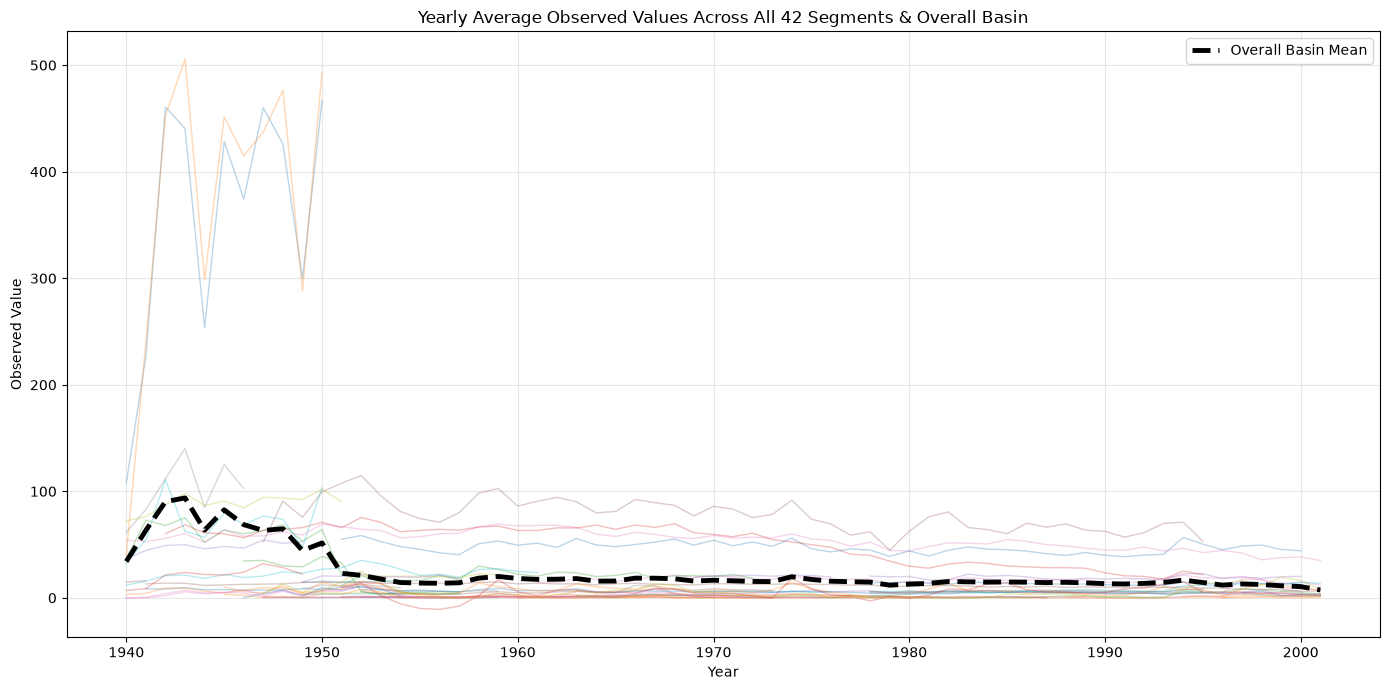

Excluding outlier segments from zoomed plot (Main-Stem Giants): [256, 239]


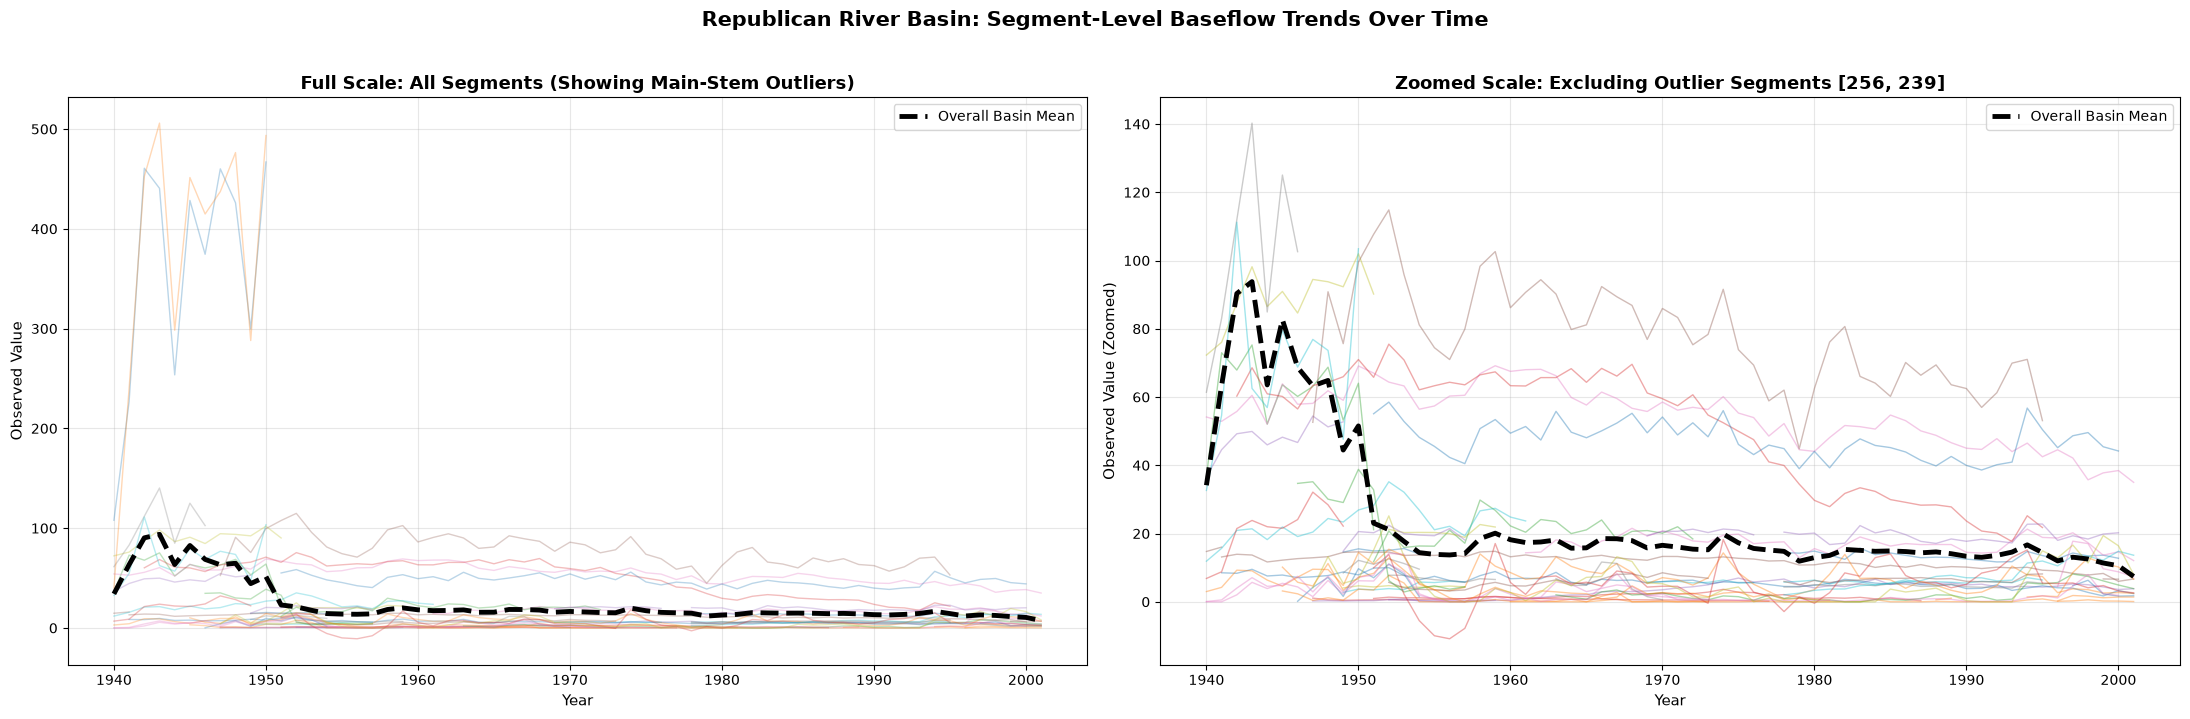

In [1092]:




# 2. Group by Year and Segment for ALL segments (no filtering)
segment_yearly = df.groupby(['Year', 'Segment_id'])['Observed'].mean().unstack()

# 3. Calculate the overall mean across all segments for each year
segment_yearly['Overall Mean'] = df.groupby('Year')['Observed'].mean()

# 4. Plotting
plt.figure(figsize=(14, 7))

for col in segment_yearly.columns:
  if col == 'Overall Mean':
    # Style the overall mean distinctly so it stands out prominently
    plt.plot(
        segment_yearly.index,
        segment_yearly[col],
        label='Overall Basin Mean',
        color='black',
        linewidth=3.5,
        linestyle='--',
        zorder=10,
    )
  else:
    # Plot individual segment lines with low opacity (alpha) to avoid a cluttered legend/view
    plt.plot(
        segment_yearly.index,
        segment_yearly[col],
        alpha=0.3,
        linewidth=1,
        label='_nolegend_',
    )

plt.title(
    'Yearly Average Observed Values Across All 42 Segments & Overall Basin'
)
plt.xlabel('Year')
plt.ylabel('Observed Value')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


import matplotlib.pyplot as plt
import pandas as pd

# 2. Group by Year and Segment for ALL segments
segment_yearly = df.groupby(['Year', 'Segment_id'])['Observed'].mean().unstack()
segment_yearly['Overall Mean'] = df.groupby('Year')['Observed'].mean()

# 3. Automatically identify the top 2 outlier segments with the highest flow
segment_means = segment_yearly.drop(columns=['Overall Mean']).mean()
top_outliers = segment_means.nlargest(2).index.tolist()
print(
    f'Excluding outlier segments from zoomed plot (Main-Stem Giants):'
    f' {top_outliers}'
)

# Set up side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(22, 7))

# ==========================================
# PLOT 1: FULL SCALE (All Segments)
# ==========================================
for col in segment_yearly.columns:
  if col == 'Overall Mean':
    axes[0].plot(
        segment_yearly.index,
        segment_yearly[col],
        label='Overall Basin Mean',
        color='black',
        linewidth=3.5,
        linestyle='--',
        zorder=10,
    )
  else:
    axes[0].plot(
        segment_yearly.index,
        segment_yearly[col],
        alpha=0.3,
        linewidth=1,
        label='_nolegend_',
    )

axes[0].set_title(
    'Full Scale: All Segments (Showing Main-Stem Outliers)',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel('Year', fontsize=11)
axes[0].set_ylabel('Observed Value', fontsize=11)
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)


# ==========================================
# PLOT 2: ZOOMED SCALE (Excluding Outliers)
# ==========================================
segment_yearly_zoomed = segment_yearly.drop(columns=top_outliers)

for col in segment_yearly_zoomed.columns:
  if col == 'Overall Mean':
    axes[1].plot(
        segment_yearly_zoomed.index,
        segment_yearly_zoomed[col],
        label='Overall Basin Mean',
        color='black',
        linewidth=3.5,
        linestyle='--',
        zorder=10,
    )
  else:
    axes[1].plot(
        segment_yearly_zoomed.index,
        segment_yearly_zoomed[col],
        alpha=0.4,
        linewidth=1,
        label='_nolegend_',
    )

axes[1].set_title(
    f'Zoomed Scale: Excluding Outlier Segments {top_outliers}',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('Year', fontsize=11)
axes[1].set_ylabel('Observed Value (Zoomed)', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

# Overall layout polish
plt.suptitle(
    'Republican River Basin: Segment-Level Baseflow Trends Over Time',
    fontsize=15,
    fontweight='bold',
    y=1.02,
)
plt.tight_layout()
plt.show()

notes 1940 is so low becues it does not have the full year of data

at first the data set was not tracking very many check points and the few that they where checking 

main-stem dams and reservoirs across the Republican River Basin (such as Harlan County Lake and Swanson Lake) between 1949 and 1953, those exact valley floors were permanently flooded and converted into regulated reservoir pools. Natural free-flowing segment accounting at those specific geographic coordinates was retired or entirely restructured.

something I found out doing my resarch is 

Low-Numbered Segments (e.g., 51, 55, 56): These typically represent small, localized headwater streams, minor creeks, or upper sub-basins. Because they drain very small areas, their natural baseflow and observed water volumes are tiny (often close to 0 or under 2 units).

High-Numbered Segments (e.g., 239, 256): These represent the main stem of major river channels or primary downstream confluences (such as the main trunk of the Republican River approaching major state-line gaging stations).

what I think we should do we will need to make a pre- and post-1950 model



In [1093]:



# 2. Sort critically by segment and time before creating lags
df = df.sort_values(by=['Segment_id', 'datetime']).reset_index(drop=True)


# 3. Function to build lagged features grouped by each Segment
def add_all_lags(subset_df):
  subset_df = subset_df.copy()

  # Precipitation lags (1 and 2 months back)
  subset_df['Precip_lag1'] = subset_df.groupby('Segment_id')[
      'Precipitation'
  ].shift(1)
  subset_df['Precip_lag2'] = subset_df.groupby('Segment_id')[
      'Precipitation'
  ].shift(2)

  # Evapotranspiration lag (1 month back)
  subset_df['Evap_lag1'] = subset_df.groupby('Segment_id')[
      'Evapotranspiration'
  ].shift(1)

  # Autoregressive lag (Flow from last month)
  subset_df['Observed_lag1'] = subset_df.groupby('Segment_id')['Observed'].shift(
      1
  )

  # Drop rows with NaNs created by shifting the first two months of each segment
  subset_df = subset_df.dropna()
  return subset_df


# Apply lagging to the entire dataset first
df_lagged = add_all_lags(df)

# 4. Split into Pre-1950 and Post-1950 Eras
df_pre = df_lagged[df_lagged['Year'] < 1951].copy()
df_post = df_lagged[df_lagged['Year'] >= 1951].copy()


# 5. Function to format feature table (X) and target vector (y)
def prepare_tables(subset_df):
  # Select all numerical features (current + lags) plus Segment_id
  feature_cols = [
      'Precipitation',
      'Evapotranspiration',
      'Irrigation_pumping',
      'Precip_lag1',
      'Precip_lag2',
      'Evap_lag1',
      'Observed_lag1',
      'Segment_id',
  ]

  data = subset_df[feature_cols].copy()

  # One-hot encode Segment_id (drop_first=True prevents the dummy variable trap)
  X = pd.get_dummies(data, columns=['Segment_id'], drop_first=True)
  y = subset_df['Observed']

  return X, y


# Build final training tables for both eras
X_pre, y_pre = prepare_tables(df_pre)
X_post, y_post = prepare_tables(df_post)

# 6. Train and Evaluate Pre-1951 Model
model_pre = LinearRegression()
model_pre.fit(X_pre, y_pre)
preds_pre = model_pre.predict(X_pre)
print(f'=== Pre-1951 Era Model ===')
print(f'Training Samples: {len(y_pre)}')
print(f'R2 Score: {r2_score(y_pre, preds_pre):.4f}')

# 7. Train and Evaluate Post-1951 Model (Regulated Era)
model_post = LinearRegression()
model_post.fit(X_post, y_post)
preds_post = model_post.predict(X_post)
print(f'\n=== Post-1950 Era Model (Dams & Regulation) ===')
print(f'Training Samples: {len(y_post)}')
print(f'R2 Score: {r2_score(y_post, preds_post):.4f}')
print("pre 19501table")
display(df_pre)
print("post 1951 table")
display(df_post)

=== Pre-1951 Era Model ===
Training Samples: 2528
R2 Score: 0.9118

=== Post-1950 Era Model (Dams & Regulation) ===
Training Samples: 12979
R2 Score: 0.9858
pre 19501table


,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,datetime,Year,Precip_lag1,Precip_lag2,Evap_lag1,Observed_lag1
2,711828,40,1798990,14561280,0.22,20.68,0.0,16.007097,1949-12-02,1949,20.68,20.68,0.05,15.497054
3,711859,40,1798990,14561280,0.00,29.07,0.0,15.877097,1950-01-02,1950,20.68,20.68,0.22,16.007097
4,711887,40,1798990,14561280,0.16,29.07,0.0,15.828305,1950-01-30,1950,29.07,20.68,0.00,15.877097
5,711918,40,1798990,14561280,0.15,29.07,0.0,15.868305,1950-03-02,1950,29.07,29.07,0.16,15.828305
6,711948,40,1798990,14561280,1.73,29.07,0.0,15.849590,1950-04-01,1950,29.07,29.07,0.15,15.868305
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15586,711948,256,1941550,14524320,1.73,30.85,0.0,655.172131,1950-04-01,1950,30.85,30.85,0.15,539.610169
15587,711979,256,1941550,14524320,2.32,30.85,0.0,739.672130,1950-05-02,1950,30.85,30.85,1.73,655.172131
15588,712009,256,1941550,14524320,4.41,30.85,0.0,697.475410,1950-06-01,1950,30.85,30.85,2.32,739.672130
15589,712040,256,1941550,14524320,8.19,30.85,0.0,515.475410,1950-07-02,1950,30.85,30.85,4.41,697.475410


post 1951 table


,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,datetime,Year,Precip_lag1,Precip_lag2,Evap_lag1,Observed_lag1
15,712224,40,1798990,14561280,0.67,26.2,0.0,15.194194,1951-01-02,1951,29.07,29.07,0.69,15.454194
16,712252,40,1798990,14561280,0.52,26.2,0.0,15.453559,1951-01-30,1951,26.20,29.07,0.67,15.194194
17,712283,40,1798990,14561280,1.19,26.2,0.0,16.313559,1951-03-02,1951,26.20,26.20,0.52,15.453559
18,712313,40,1798990,14561280,3.25,26.2,0.0,16.047869,1951-04-01,1951,26.20,26.20,1.19,16.313559
19,712344,40,1798990,14561280,4.50,26.2,0.0,14.507869,1951-05-02,1951,26.20,26.20,3.25,16.047869
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15232,730607,196,1482190,14577120,0.00,0.0,0.0,8.685246,2001-05-02,2001,0.00,0.00,0.00,13.821667
15233,730637,196,1482190,14577120,0.00,0.0,0.0,3.570492,2001-06-01,2001,0.00,0.00,0.00,8.685246
15234,730668,196,1482190,14577120,0.00,0.0,0.0,1.727869,2001-07-02,2001,0.00,0.00,0.00,3.570492
15235,730699,196,1482190,14577120,0.00,0.0,0.0,0.000000,2001-08-02,2001,0.00,0.00,0.00,1.727869


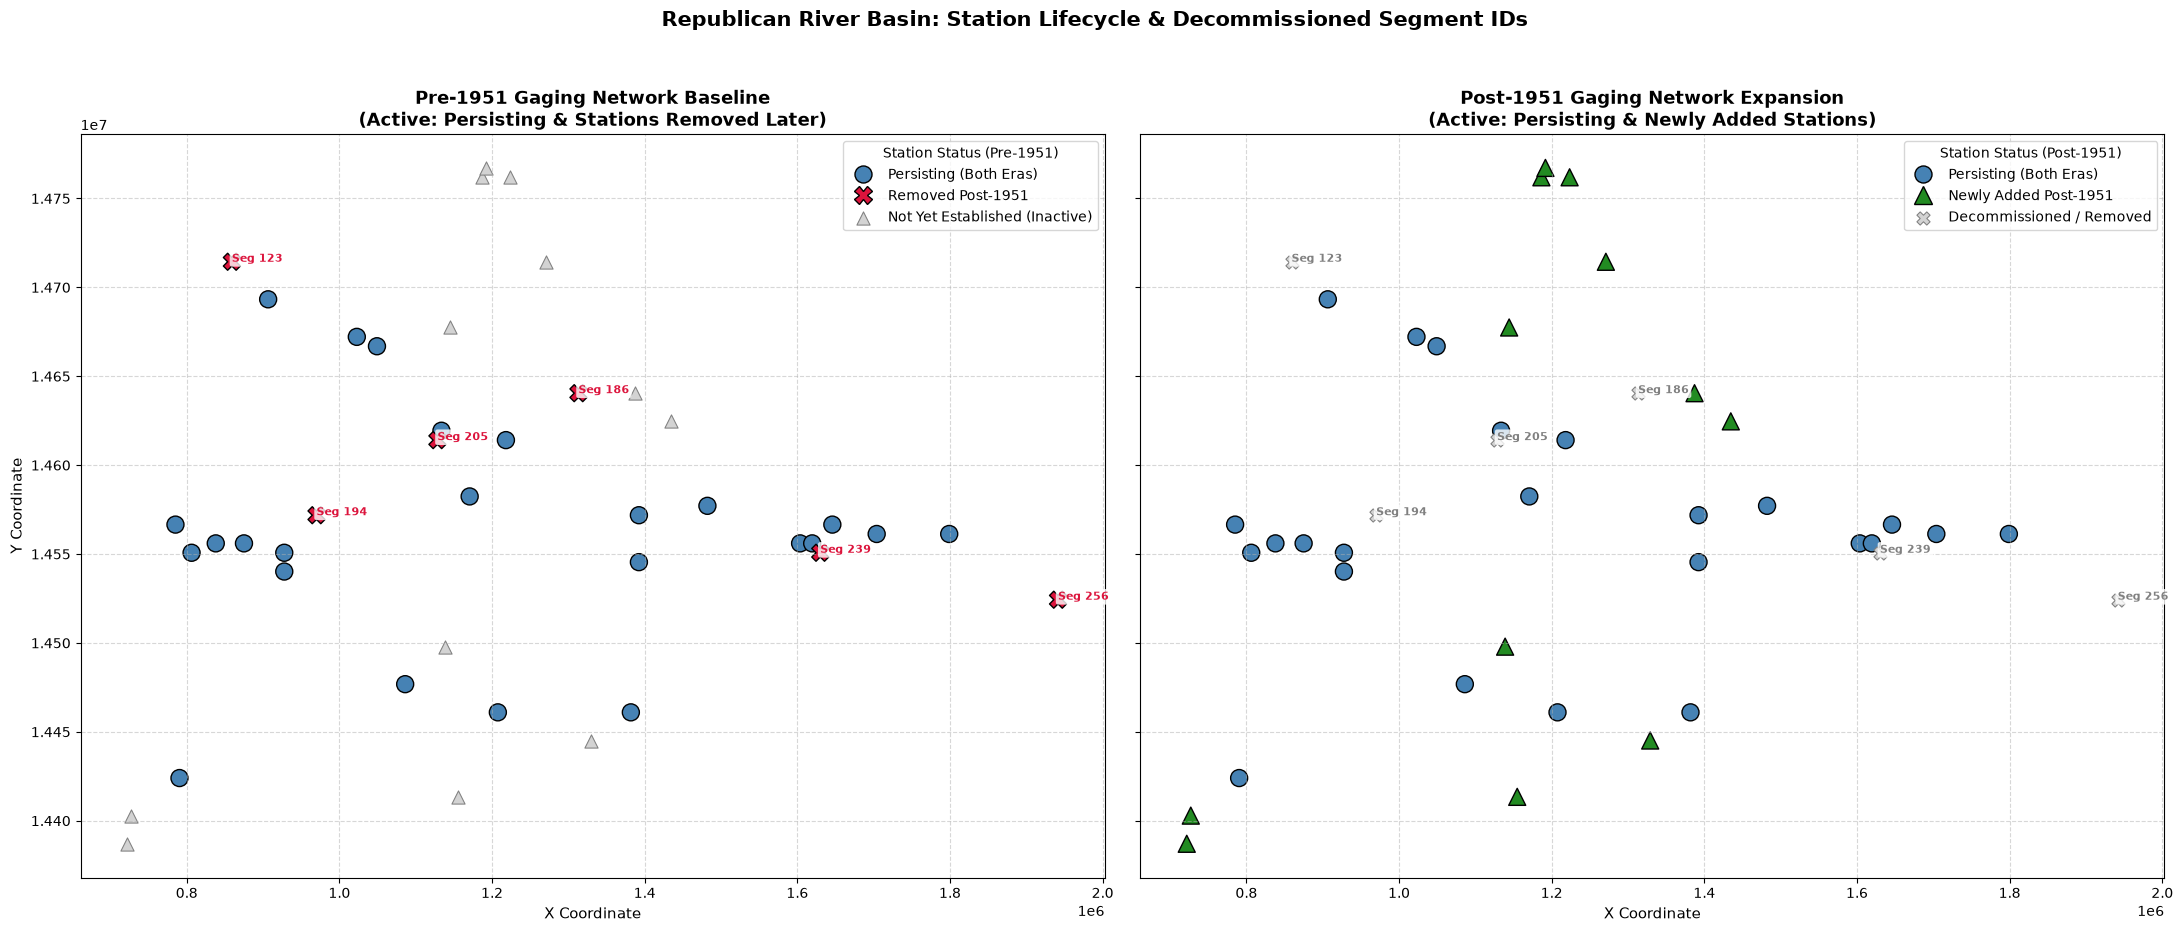

In [1094]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ==========================================
# 1. IDENTIFY PERSISTING & SHIFTING STATIONS
# ==========================================
stations_pre = df_pre.drop_duplicates(subset=['Segment_id'])
stations_post = df_post.drop_duplicates(subset=['Segment_id'])

ids_pre = set(stations_pre['Segment_id'])
ids_post = set(stations_post['Segment_id'])

# Master station dataframe containing all unique segments ever recorded
master_stations = df.drop_duplicates(subset=['Segment_id']).copy()


# ==========================================
# 2. SMART CLASSIFICATION FUNCTION
# (Catches stations that died out mid-1951)
# ==========================================
def classify_station_smart(seg_id):
  post_rows = df_post[df_post['Segment_id'] == seg_id]

  # If no post-1951 rows exist at all
  if post_rows.empty:
    return 'Removed Post-1951'

  max_post_date = post_rows['datetime'].max()
  post_count = len(post_rows)

  # If it stopped recording in 1951 with less than 12 months of data
  if max_post_date.year == 1950 and post_count < 12:
    return 'Removed Post-1951'

  # Otherwise check normal persistence
  if seg_id in ids_pre and seg_id in ids_post:
    return 'Persisting (Both Eras)'
  elif seg_id in ids_pre:
    return 'Removed Post-1951'
  else:
    return 'Newly Added Post-1951'


# Apply the smart classification
master_stations['Lifecycle_Status'] = master_stations['Segment_id'].apply(
    classify_station_smart
)

# Extract specifically the removed stations for text labeling
removed_df = master_stations[
    master_stations['Lifecycle_Status'] == 'Removed Post-1951'
]


# ==========================================
# 3. SETUP SIDE-BY-SIDE SPATIAL MAPS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(22, 9), sharex=True, sharey=True)

palette = {
    'Persisting (Both Eras)': 'steelblue',
    'Removed Post-1951': 'crimson',
    'Newly Added Post-1951': 'forestgreen',
}
markers = {
    'Persisting (Both Eras)': 'o',
    'Removed Post-1951': 'X',
    'Newly Added Post-1951': '^',
}


# ------------------------------------------
# MAP 1: PRE-1951 ERA VIEW
# ------------------------------------------
active_pre = master_stations[
    master_stations['Lifecycle_Status'].isin(
        ['Persisting (Both Eras)', 'Removed Post-1951']
    )
]
inactive_pre = master_stations[
    master_stations['Lifecycle_Status'] == 'Newly Added Post-1951'
]

sns.scatterplot(
    data=active_pre,
    x='x',
    y='y',
    hue='Lifecycle_Status',
    style='Lifecycle_Status',
    palette=palette,
    markers=markers,
    s=150,
    edgecolor='black',
    linewidth=1,
    ax=axes[0],
)
sns.scatterplot(
    data=inactive_pre,
    x='x',
    y='y',
    color='lightgray',
    marker='^',
    s=90,
    edgecolor='gray',
    ax=axes[0],
    label='Not Yet Established (Inactive)',
)

# Label removed stations (like 205, 239, 256) on the Pre-1951 map
for _, row in removed_df.iterrows():
  axes[0].text(
      row['x'] + 0.5,
      row['y'] + 0.5,
      f"Seg {int(row['Segment_id'])}",
      fontsize=8,
      fontweight='bold',
      color='crimson',
      bbox=dict(
          boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='none'
      ),
  )

axes[0].set_title(
    'Pre-1951 Gaging Network Baseline\n(Active: Persisting & Stations Removed'
    ' Later)',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel('X Coordinate', fontsize=11)
axes[0].set_ylabel('Y Coordinate', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='Station Status (Pre-1951)', loc='upper right', frameon=True)


# ------------------------------------------
# MAP 2: POST-1951 ERA VIEW
# ------------------------------------------
active_post = master_stations[
    master_stations['Lifecycle_Status'].isin(
        ['Persisting (Both Eras)', 'Newly Added Post-1951']
    )
]
inactive_post = master_stations[
    master_stations['Lifecycle_Status'] == 'Removed Post-1951'
]

sns.scatterplot(
    data=active_post,
    x='x',
    y='y',
    hue='Lifecycle_Status',
    style='Lifecycle_Status',
    palette=palette,
    markers=markers,
    s=150,
    edgecolor='black',
    linewidth=1,
    ax=axes[1],
)
sns.scatterplot(
    data=inactive_post,
    x='x',
    y='y',
    color='lightgray',
    marker='X',
    s=90,
    edgecolor='gray',
    ax=axes[1],
    label='Decommissioned / Removed',
)

# Label the same removed stations on the Post-1951 map so you can see where they vanished
for _, row in removed_df.iterrows():
  axes[1].text(
      row['x'] + 0.5,
      row['y'] + 0.5,
      f"Seg {int(row['Segment_id'])}",
      fontsize=8,
      fontweight='bold',
      color='gray',
      bbox=dict(
          boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='none'
      ),
  )

axes[1].set_title(
    'Post-1951 Gaging Network Expansion\n(Active: Persisting & Newly Added'
    ' Stations)',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('X Coordinate', fontsize=11)
axes[1].set_ylabel('Y Coordinate', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(title='Station Status (Post-1951)', loc='upper right', frameon=True)

# Overall layout polish
plt.suptitle(
    'Republican River Basin: Station Lifecycle & Decommissioned Segment IDs',
    fontsize=15,
    fontweight='bold',
    y=1.03,
)
plt.tight_layout()
plt.show()

base flow is the amount of ground water entering the river or stream at some point 

so a postive base flow means more water is entering a stream or river then leaveing

so a negtive base flow means more water is leaving a stream or river from leaking into the ground then comeing in

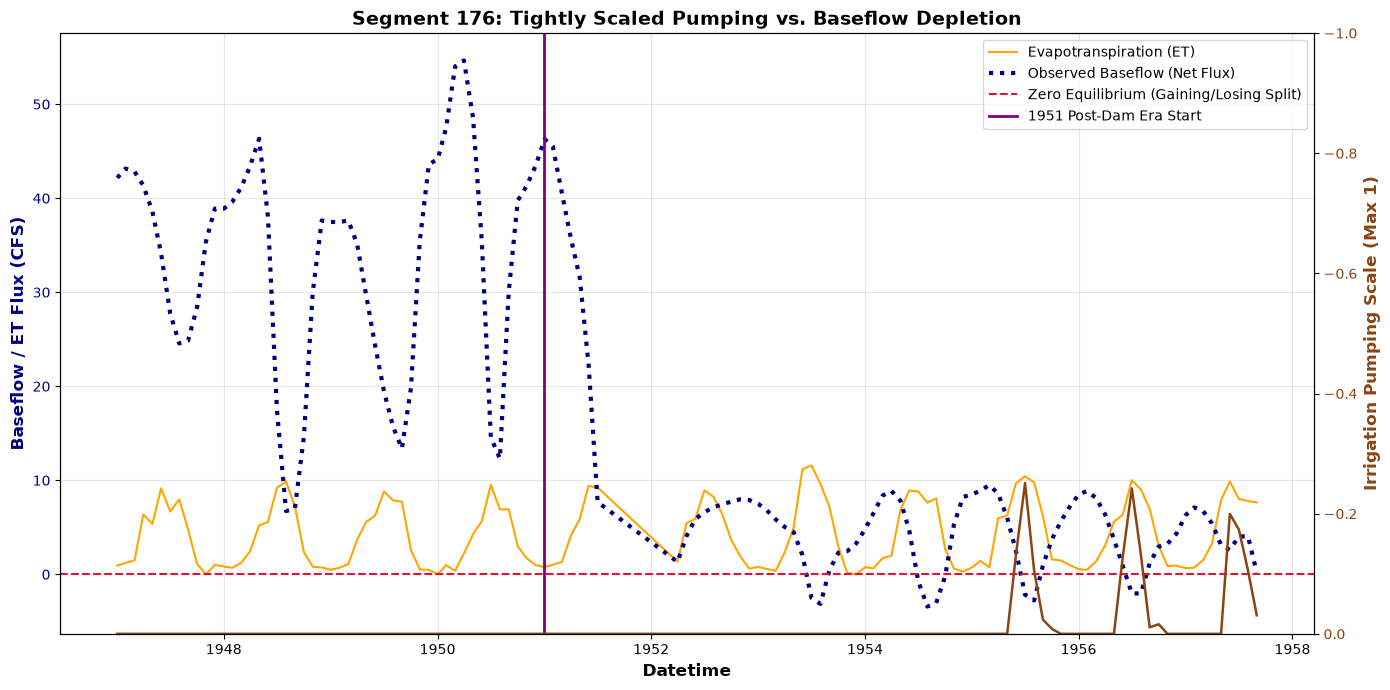

In [1095]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Isolate Segment 176 and sort chronologically
seg_176 = df_lagged[df_lagged['Segment_id'] == 176].sort_values(
    'datetime'
).copy()
seg_176['datetime'] = pd.to_datetime(seg_176['datetime'])

# 2. Set up the figure with dual axes
fig, ax1 = plt.subplots(figsize=(14, 7))
ax2 = ax1.twinx()

# ==========================================
# LEFT AXIS (ax1): Baseflow & Evapotranspiration
# ==========================================
l1 = ax1.plot(
    seg_176['datetime'],
    seg_176['Evapotranspiration'],
    color='orange',
    linewidth=1.5,
    label='Evapotranspiration (ET)',
)
l2 = ax1.plot(
    seg_176['datetime'],
    seg_176['Observed'],
    color='navy',
    linestyle=':',
    linewidth=3.0,
    label='Observed Baseflow (Net Flux)',
)

ax1.set_ylabel(
    'Baseflow / ET Flux (CFS)', color='navy', fontsize=12, fontweight='bold'
)
ax1.tick_params(axis='y', labelcolor='navy')

# ==========================================
# RIGHT AXIS (ax2): Irrigation Pumping & Precipitation
# ==========================================
l3 = ax2.plot(
    seg_176['datetime'],
    seg_176['Irrigation_pumping'],
    color='saddlebrown',
    linewidth=1.8,
    label='Irrigation Pumping',
)
l4 = ax2.plot(
    seg_176['datetime'],
    seg_176['Precipitation'],
    color='deepskyblue',
    linewidth=1.2,
    alpha=0.7,
    label='Precipitation',
)

ax2.set_ylabel(
    'Irrigation Pumping Scale (Max 1)',
    color='saddlebrown',
    fontsize=12,
    fontweight='bold',
)
ax2.tick_params(axis='y', labelcolor='saddlebrown')

# ** TIGHTLY PIN THE RIGHT AXIS TO A MAX OF 1 **
ax2.set_ylim(0, -1)

# ==========================================
# REFERENCE LINES & LEGEND
# ==========================================
# Zero line for baseflow on the left axis
ax1.axhline(
    0,
    color='crimson',
    linestyle='--',
    linewidth=1.5,
    label='Zero Equilibrium (Gaining/Losing Split)',
)

# 1951 Post-Dam Era Line
ax1.axvline(
    pd.to_datetime('1951-01-01'),
    color='purple',
    linestyle='-',
    linewidth=2.0,
    label='1951 Post-Dam Era Start',
)

# Combine legends from both axes into one neat box
lines = l1 + l2 + l3 + l4
ax1.legend(loc='upper right', frameon=True, fontsize=10)

# Formatting
plt.title(
    'Segment 176: Tightly Scaled Pumping vs. Baseflow Depletion',
    fontsize=14,
    fontweight='bold',
)
ax1.set_xlabel('Datetime', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()










Config [BASIC] -> Pre R2: 0.7745 | Post R2: 0.8831
Config [ENV_LAGS] -> Pre R2: 0.8030 | Post R2: 0.8882
Config [EWM_BALANCE] -> Pre R2: 0.7869 | Post R2: 0.8864
Config [ENV_LAGS_PLUS_EWM] -> Pre R2: 0.8046 | Post R2: 0.8894
Config [FULL_COMBINED] -> Pre R2: 0.9118 | Post R2: 0.9859


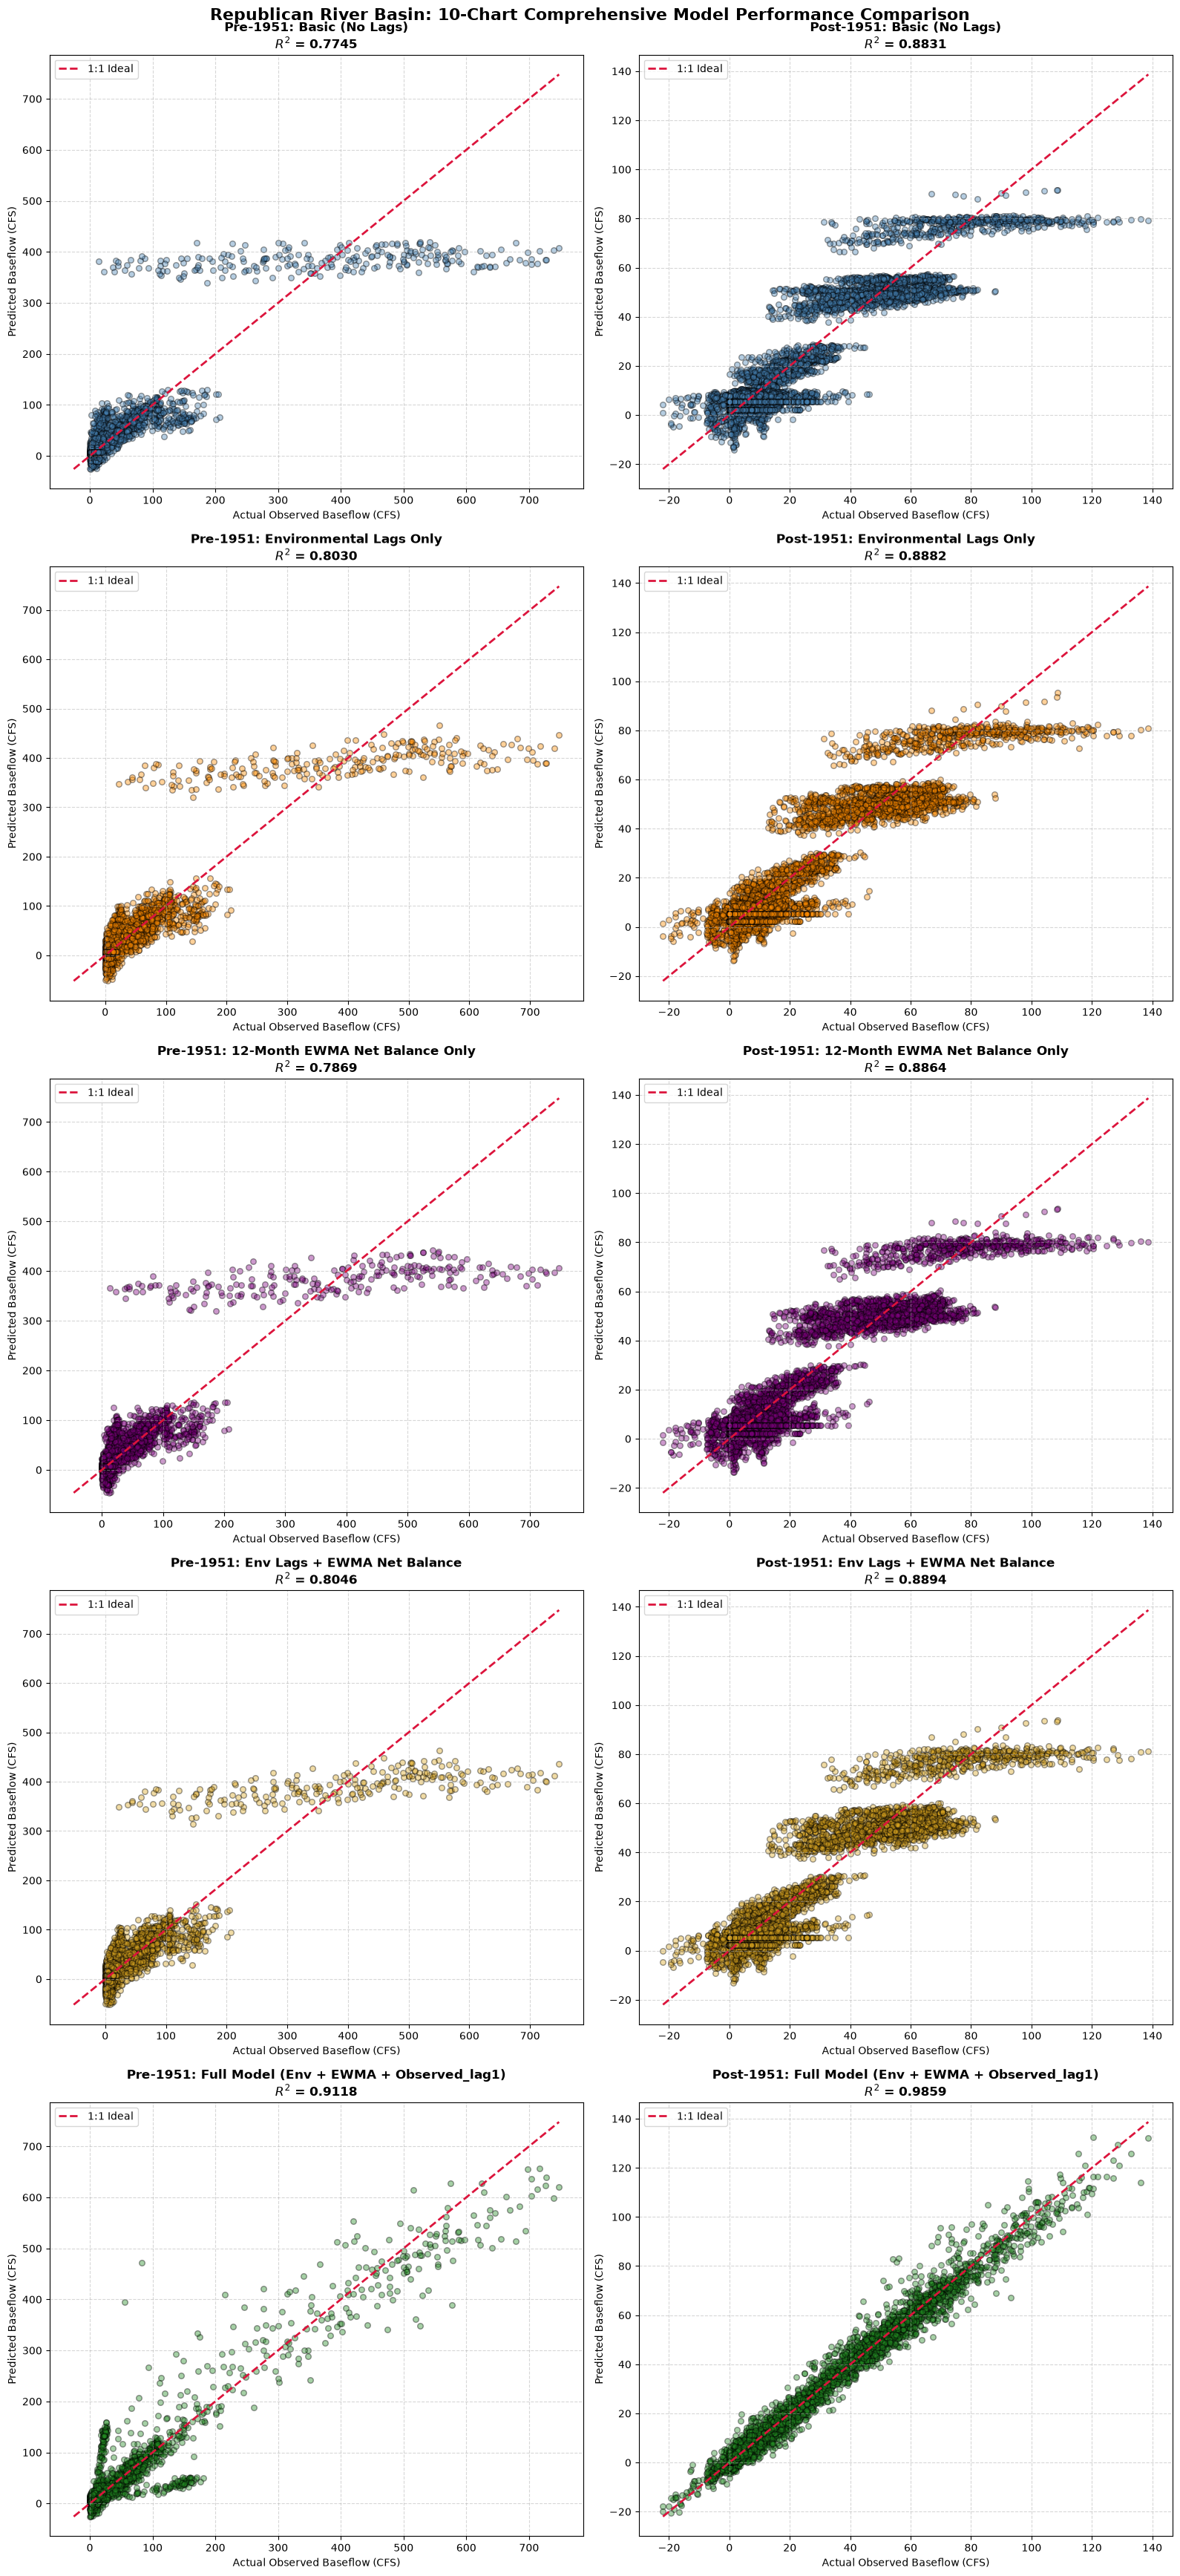

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# ==========================================
# 0. PREPARATION, DATES & PUMPING CORRECTION
# ==========================================
if 'datetime' not in df.columns and 'Date' in df.columns:
  df['datetime'] = pd.to_datetime(
      df['Date'] - 693963, unit='D', origin='1900-01-01'
  )

df['Year'] = pd.to_datetime(df['datetime']).dt.year

# Sort critically by segment and time before calculating features
df = df.sort_values(by=['Segment_id', 'datetime']).reset_index(drop=True)

# Convert irrigation pumping to a positive magnitude of extraction (.abs())
df['Irrigation_pumping'] = df['Irrigation_pumping'].abs()

# Calculate Monthly Net Water Balance (Rain - ET - Pumping)
df['Net_Water_Balance'] = (
    df['Precipitation'] - df['Evapotranspiration'] - df['Irrigation_pumping']
)


# ==========================================
# 1. CREATE ALL FEATURES (Lags & EWMA Memory)
# ==========================================
def add_features(subset_df):
  df_out = subset_df.copy()

  # Environmental Lags
  df_out['Precip_lag1'] = (
      df_out.groupby('Segment_id')['Precipitation'].shift(1)
  )
  df_out['Precip_lag2'] = (
      df_out.groupby('Segment_id')['Precipitation'].shift(2)
  )
  df_out['Evap_lag1'] = (
      df_out.groupby('Segment_id')['Evapotranspiration'].shift(1)
  )

  # Autoregressive Lag (Last month's observed flow)
  df_out['Observed_lag1'] = df_out.groupby('Segment_id')['Observed'].shift(1)

  # 12-Month EWMA Net Water Balance (Captures exponential aquifer memory decay)
  df_out['Net_Balance_EWMA12'] = (
      df_out.groupby('Segment_id')['Net_Water_Balance']
      .ewm(span=12, adjust=False)
      .mean()
      .reset_index(0, drop=True)
  )

  return df_out


df_featured = add_features(df)

# Split into Pre-1951 and Post-1951 Eras
df_pre_raw = df_featured[df_featured['Year'] < 1951].copy()
df_post_raw = df_featured[df_featured['Year'] >= 1951].copy()


# ==========================================
# 2. ROBUST TABLE PREPARATION (5 Configurations)
# ==========================================
def prep_model_data(subset_df, model_type):
  if model_type == 'basic':
    cols = [
        'Precipitation',
        'Evapotranspiration',
        'Irrigation_pumping',
        'Segment_id',
        'Observed',
    ]
  elif model_type == 'env_lags':
    cols = [
        'Precipitation',
        'Evapotranspiration',
        'Irrigation_pumping',
        'Precip_lag1',
        'Precip_lag2',
        'Evap_lag1',
        'Segment_id',
        'Observed',
    ]
  elif model_type == 'ewm_balance':
    cols = [
        'Precipitation',
        'Evapotranspiration',
        'Irrigation_pumping',
        'Net_Balance_EWMA12',
        'Segment_id',
        'Observed',
    ]
  elif model_type == 'env_lags_plus_ewm':
    cols = [
        'Precipitation',
        'Evapotranspiration',
        'Irrigation_pumping',
        'Precip_lag1',
        'Precip_lag2',
        'Evap_lag1',
        'Net_Balance_EWMA12',
        'Segment_id',
        'Observed',
    ]
  elif model_type == 'full_combined':
    cols = [
        'Precipitation',
        'Evapotranspiration',
        'Irrigation_pumping',
        'Precip_lag1',
        'Precip_lag2',
        'Evap_lag1',
        'Observed_lag1',
        'Net_Balance_EWMA12',
        'Segment_id',
        'Observed',
    ]

  temp = subset_df[cols].dropna()
  X = pd.get_dummies(
      temp.drop(columns=['Observed']), columns=['Segment_id'], drop_first=True
  )
  y = temp['Observed']
  return X, y


configs = [
    'basic',
    'env_lags',
    'ewm_balance',
    'env_lags_plus_ewm',
    'full_combined',
]
results = {}

for cfg in configs:
  X_pre, y_pre = prep_model_data(df_pre_raw, cfg)
  X_post, y_post = prep_model_data(df_post_raw, cfg)

  m_pre = LinearRegression().fit(X_pre, y_pre)
  m_post = LinearRegression().fit(X_post, y_post)

  p_pre = m_pre.predict(X_pre)
  p_post = m_post.predict(X_post)

  results[cfg] = {
      'y_pre': y_pre,
      'p_pre': p_pre,
      'r2_pre': r2_score(y_pre, p_pre),
      'y_post': y_post,
      'p_post': p_post,
      'r2_post': r2_score(y_post, p_post),
  }

# Print performance summary
for cfg in configs:
  print(
      f'Config [{cfg.upper()}] -> Pre R2: {results[cfg]["r2_pre"]:.4f} | Post'
      f' R2: {results[cfg]["r2_post"]:.4f}'
  )


# ==========================================
# 3. PLOTTING THE 10-CHART GRID (5 Rows x 2 Cols)
# ==========================================
fig, axes = plt.subplots(5, 2, figsize=(16, 35))


def plot_parity(ax, y_true, y_pred, title, r2, color='teal'):
  ax.scatter(y_true, y_pred, alpha=0.4, color=color, edgecolor='k', s=30)
  min_val = min(y_true.min(), y_pred.min())
  max_val = max(y_true.max(), y_pred.max())
  ax.plot(
      [min_val, max_val],
      [min_val, max_val],
      color='crimson',
      linestyle='--',
      linewidth=2,
      label='1:1 Ideal',
  )
  ax.set_title(f'{title}\n$R^2$ = {r2:.4f}', fontsize=12, fontweight='bold')
  ax.set_xlabel('Actual Observed Baseflow (CFS)', fontsize=10)
  ax.set_ylabel('Predicted Baseflow (CFS)', fontsize=10)
  ax.grid(True, linestyle='--', alpha=0.5)
  ax.legend(loc='upper left')


# Row 1: Basic (No Lags)
plot_parity(
    axes[0, 0],
    results['basic']['y_pre'],
    results['basic']['p_pre'],
    'Pre-1951: Basic (No Lags)',
    results['basic']['r2_pre'],
    'steelblue',
)
plot_parity(
    axes[0, 1],
    results['basic']['y_post'],
    results['basic']['p_post'],
    'Post-1951: Basic (No Lags)',
    results['basic']['r2_post'],
    'steelblue',
)

# Row 2: Environmental Lags Only
plot_parity(
    axes[1, 0],
    results['env_lags']['y_pre'],
    results['env_lags']['p_pre'],
    'Pre-1951: Environmental Lags Only',
    results['env_lags']['r2_pre'],
    'darkorange',
)
plot_parity(
    axes[1, 1],
    results['env_lags']['y_post'],
    results['env_lags']['p_post'],
    'Post-1951: Environmental Lags Only',
    results['env_lags']['r2_post'],
    'darkorange',
)

# Row 3: 12-Month EWMA Net Balance Only
plot_parity(
    axes[2, 0],
    results['ewm_balance']['y_pre'],
    results['ewm_balance']['p_pre'],
    'Pre-1951: 12-Month EWMA Net Balance Only',
    results['ewm_balance']['r2_pre'],
    'purple',
)
plot_parity(
    axes[2, 1],
    results['ewm_balance']['y_post'],
    results['ewm_balance']['p_post'],
    'Post-1951: 12-Month EWMA Net Balance Only',
    results['ewm_balance']['r2_post'],
    'purple',
)

# Row 4: Environmental Lags + EWMA Net Balance Combined
plot_parity(
    axes[3, 0],
    results['env_lags_plus_ewm']['y_pre'],
    results['env_lags_plus_ewm']['p_pre'],
    'Pre-1951: Env Lags + EWMA Net Balance',
    results['env_lags_plus_ewm']['r2_pre'],
    'goldenrod',
)
plot_parity(
    axes[3, 1],
    results['env_lags_plus_ewm']['y_post'],
    results['env_lags_plus_ewm']['p_post'],
    'Post-1951: Env Lags + EWMA Net Balance',
    results['env_lags_plus_ewm']['r2_post'],
    'goldenrod',
)

# Row 5: Full Combined Model (Env Lags + EWMA + Observed_lag1)
plot_parity(
    axes[4, 0],
    results['full_combined']['y_pre'],
    results['full_combined']['p_pre'],
    'Pre-1951: Full Model (Env + EWMA + Observed_lag1)',
    results['full_combined']['r2_pre'],
    'forestgreen',
)
plot_parity(
    axes[4, 1],
    results['full_combined']['y_post'],
    results['full_combined']['p_post'],
    'Post-1951: Full Model (Env + EWMA + Observed_lag1)',
    results['full_combined']['r2_post'],
    'forestgreen',
)

plt.suptitle(
    'Republican River Basin: 10-Chart Comprehensive Model Performance'
    ' Comparison',
    fontsize=16,
    fontweight='bold',
    y=0.99,
)
plt.tight_layout()
plt.show()



ewma stands for exponentially weighted moving average it gives the more recent months more value